# Ronda 007: características de negación y contraste
La instrucción del usuario autoriza implementar el plan `revision_006_y_plan_007.md`. Sus afirmaciones se contrastan, no se asumen como resultados ya comprobados. Las reglas de esta ejecución están en `plan_007.json`. La referencia es 005, conservando 006 para trazabilidad.

In [1]:
from pathlib import Path
import os,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
if not Path('reports/registro_007.json').exists():os.chdir('..')
r=json.loads(Path('reports/registro_007.json').read_text())
display(Markdown(Path('reports/resumen_007.md').read_text()))
cv=pd.read_csv('reports/resultados_cv_007.csv')
display(cv)
display(pd.read_csv('reports/criterios_007.csv'))
display(r['historical'])

# Experimento 007 — negación, contraste y estabilidad

La ronda se ejecutó con cuatro candidatos, tres semillas y tres folds por semilla. Todos los scores intervienen en la selección; no son una evaluación independiente. Se preservó la prueba local antigua. Cambiar semillas no elimina el historial de exploración.

| Candidato | F1 macro OOF medio entre semillas | Brecha media |
|---|---:|---:|
| c1_min5 | 0.873633 | 0.121717 |
| neg_scope | 0.873354 | 0.126302 |
| post_contraste | 0.873522 | 0.126107 |
| ref005 | 0.874195 | 0.125401 |

## Criterios y decisión

Cada semilla: delta F1 OOF >=0.005 vs005 y ganar 3 folds o >=2 con menor brecha media. Debe cumplir las tres semillas. Luego no perder F1 OOF en semilla histórica137. Entre aprobados mayor F1 medio en semillas nuevas; empate exacto menor brecha.

Ganadora: ninguna. CSV nuevo creado: False.
Conservar005: ninguna candidata cumple todos los criterios previos. No generar un CSV equivalente ni reducir los umbrales después de observar resultados.

## Interpretación y límites

Los canales añadidos son características, no reglas de etiqueta: no se obliga a que una negación invierta la clase ni a que la cláusula posterior al contraste domine la reseña. La negación se aproxima con tres tokens hasta puntuación o corte de contraste; no constituye análisis sintáctico completo. El canal post_contraste abarca el segmento posterior a pero/aunque/sin embargo hasta la puntuación de oración. Ambos conservan toda la representación base de 005. Peso adicional 0,35, min_df=3 y hasta 30000 rasgos se fijaron sin optimizar contra resultados.

C=1/min_df=5 combina dos cambios ya propuestos en el documento; no aísla causalmente cuál de ellos explica diferencias. El opcional char_wb no se ejecutó para mantener el presupuesto. No se borran ni reetiquetan reseñas; no se usan datos externos o sintéticos.

Se exigió +0,005 en CADA semilla, no solo en el promedio. En cada una también se exigieron tres victorias de fold, o al menos dos y brecha menor. La comparación histórica137 solo se ejecuta si una candidata supera esos requisitos. Si se usa, es otra puerta de selección, no prueba confirmatoria. La semilla271 ya se usó dentro del stacking006, aunque no como partición externa de esa versión.

El documento del auditor atribuye la caída pública de006 a adaptación a folds. Es una hipótesis plausible, no causalidad demostrada por un score público. El tamaño del delta respecto a la desviación entre folds tampoco basta para concluir señal o ruido: haría falta analizar diferencias emparejadas e incertidumbre, considerando adaptación. El documento cita ~0,87 sin captura exacta disponible en este turno; no se registra como valor exacto confirmado.

El público confirmado de005 es0,88111. La plataforma no fue consultada. No se extrapolan puntajes ni se garantiza0,90. F1 macro sigue siendo el criterio local por instrucción del usuario; las capturas no verifican la fórmula oficial.

## Reproducibilidad

Tiempo medido del experimento: 159.1 segundos. Archivos anteriores intactos: True.
Entrenamiento: `.venv/bin/python -m src.experimento_007`. Se detiene si ya existe registro_007.json para evitar sobrescribir resultados accidentalmente; archivar explícitamente la ejecución previa antes de repetir. Notebook: `.venv/bin/python src/informe_007.py`. Modelos anteriores y módulos no se modifican.


,name,seed,oof_f1,fold_mean,fold_std,train_mean,gap
0,ref005,271,0.874398,0.874389,0.001816,0.999604,0.125215
1,neg_scope,271,0.873298,0.873286,0.000992,0.999604,0.126318
2,post_contraste,271,0.874036,0.874030,0.000899,0.999654,0.125624
3,c1_min5,271,0.875391,0.875379,0.001121,0.995004,0.119625
4,ref005,599,0.871837,0.871840,0.003722,0.999555,0.127715
5,neg_scope,599,0.871738,0.871745,0.004182,0.999703,0.127958
6,post_contraste,599,0.868874,0.868877,0.001895,0.999604,0.130727
7,c1_min5,599,0.870744,0.870738,0.003709,0.995894,0.125156
8,ref005,913,0.876348,0.876281,0.000868,0.999555,0.123274
9,neg_scope,913,0.875027,0.874974,0.000879,0.999604,0.124630


,name,seed,f1_gain,folds_won,gap_change,passes
0,neg_scope,271,-0.001100,1,0.001103,False
1,neg_scope,599,-0.000099,2,0.000243,False
2,neg_scope,913,-0.001321,0,0.001357,False
3,post_contraste,271,-0.000362,1,0.000409,False
4,post_contraste,599,-0.002963,0,0.003012,False
5,post_contraste,913,0.001308,3,-0.001305,False
6,c1_min5,271,0.000993,2,-0.005590,False
7,c1_min5,599,-0.001094,0,-0.002559,False
8,c1_min5,913,-0.001583,0,-0.002905,False


{}

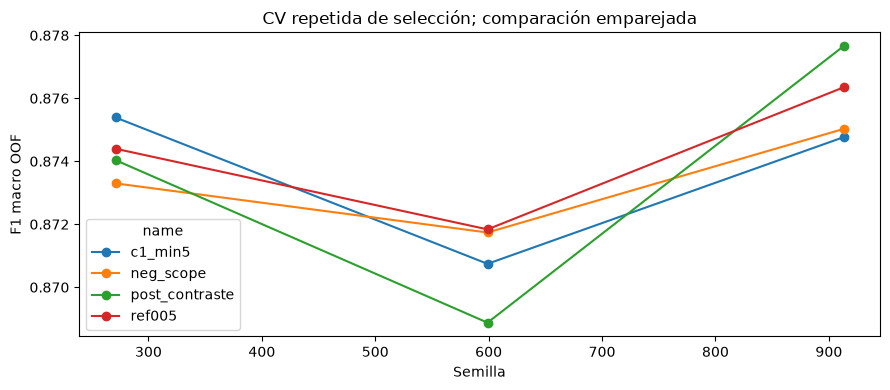

,name,seed,fold,train_f1,validation_f1,gap,iterations
0,ref005,271,0,0.999852,0.876089,0.123762,60
1,ref005,271,1,0.999406,0.871873,0.127534,60
2,ref005,271,2,0.999555,0.875206,0.124349,61
3,neg_scope,271,0,0.999852,0.874599,0.125253,61
4,neg_scope,271,1,0.999406,0.873058,0.126349,61
5,neg_scope,271,2,0.999555,0.872201,0.127354,62
6,post_contraste,271,0,1.000000,0.875301,0.124699,59
7,post_contraste,271,1,0.999406,0.873413,0.125994,59
8,post_contraste,271,2,0.999555,0.873375,0.126180,61
9,c1_min5,271,0,0.995103,0.875195,0.119909,39


In [2]:
main=cv[cv.seed.isin([271,599,913])]
ax=main.pivot(index='seed',columns='name',values='oof_f1').plot(marker='o',figsize=(9,4))
ax.set(xlabel='Semilla',ylabel='F1 macro OOF',title='CV repetida de selección; comparación emparejada')
plt.tight_layout();plt.savefig('reports/comparacion_007.png',dpi=160);plt.show()
folds=pd.read_csv('reports/folds_007.csv')
display(folds[['name','seed','fold','train_f1','validation_f1','gap','iterations']])

## Comprobaciones y límites
Todas las particiones separan grupos de texto normalizado; los vectorizadores aprenden vocabulario e IDF dentro de cada entrenamiento. Convergencia del SVM exigida como condición de ejecución. Las pruebas de la función de aceptación usan únicamente métricas de ejemplo, nunca reseñas sintéticas de entrenamiento.

Una candidata no aceptada no se exporta bajo otro número solo para fabricar un envío. Si se acepta, se reentrena con todo train tras cerrar selección y eval se usa únicamente para generar predicciones. El mismo modelo y CSV previos permanecen disponibles.

Los puntajes de selección no son pruebas externas nuevas. Ni el cambio de semilla ni las condiciones más estrictas garantizan ausencia de sobreajuste. No se utiliza la prueba local anterior ni el leaderboard para ajustar estas características.

In [3]:
display(r['source_sha256'])
print('Archivos anteriores intactos:',r['old_artifacts_unchanged'])
if r['submission_created']:
 display(r['artifacts_sha256']);display(pd.read_csv('submissions/submission_007.csv').head())
else:print(r['decision'])

{'src/experimento_007.py': '2f28fca8337c1e7980cb3976f53fb1dd91f23ccd12d6130463a9928b24215b59',
 'src/features_007.py': '11ed5f3526df5b2e775ffe12a0aa5a13a48afdca83d17c7c1344e56f7deb4270',
 'src/features_004.py': '0295e192394795168bffcb3fbd53059d045b35261ab39b2d868671cdba4f641a',
 'reports/particiones.csv': 'd90cbd30a92a366298a66f2322df4869694798392f19b9c0978dbecac104a931'}

Archivos anteriores intactos: True
Conservar005: ninguna candidata cumple todos los criterios previos. No generar un CSV equivalente ni reducir los umbrales después de observar resultados.
